# E-commerce Analytics Project
### From raw data to a Power BI dashboard

## What this notebook does
This notebook takes four raw tables and turns them into business answers. It cleans the data, checks that the tables agree with each other, runs 11 analyses with proper statistical tests, and exports tidy files for Power BI.

## The four tables
| Table | One row is... | What we use it for |
|---|---|---|
| `orders` | one order | The main record of sales. Revenue, discounts, returns and delivery all come from here |
| `customers` | one customer | Who the customer is (tier, channel, country) and whether they churned |
| `monthly_revenue` | one month | A ready-made monthly summary. We use it to **check** our numbers |
| `product_summary` | one product | A ready-made product summary. We also use it to **check** our numbers |

## How to read this notebook
Every section has the same three parts:
1. **A text box like this one** that says what the next code cell does and why.
2. **The code cell** (you can ignore the code and just read the output).
3. **"What I found"**, a short plain-English reading of the output.

## Words you will see a lot
| Word | Meaning |
|---|---|
| **Revenue** | Money from **Delivered** orders only (`total_amount_usd`). This matches the `monthly_revenue` table |
| **AOV** | Average order value: revenue divided by number of orders |
| **Churn** | A customer who has left. About 8.9% of customers are marked as churned |
| **RFM** | Recency (how recently they bought), Frequency (how often), Monetary (how much). A way to group customers |
| **CLV** | Customer lifetime value: how much a customer is worth to the business |
| **p-value** | The chance a difference is just luck. **Below 0.05 means the difference is probably real.** Above 0.05 means we cannot tell it apart from luck |
| **Adjusted p-value** | The p-value corrected because we ran many tests. If you run 40 tests, a few will look real by pure luck. This correction guards against that |

## Before you run it
- Run the cells **from top to bottom** in a fresh session (Restart, then Run All).
- In the setup cell, check the `DATA` path points to the folder that holds your four CSV files.

## Things to keep in mind
- The `orders` table looks like a **slice** of the full history (about 19% of the orders the `customers` table reports). So results from `orders` describe the sample, not every purchase ever made.
- There is **no cost or marketing spend data**, so we cannot calculate profit or return on ad spend. Margin is an assumption (30%).
- Many results below say "no difference found". That is a real finding. It means the data does not support acting on that factor.

---
## Step 0. Setup
**What this does:** loads the tools we need, tells Python where the data folder is, and sets a few business rules in one place:
- `EXCLUDE_STATUS`: orders with these statuses are not real sales ("Cancelled").
- `REVENUE_STATUS`: only **Delivered** orders count as revenue.
- `MARGIN`: we assume 30% of revenue is profit, because the data has no costs.

It also creates two helpers used all through the notebook:
- `log()` writes down every statistical test we run.
- `test_table()` shows all the tests together, with the corrected (adjusted) p-values.

**Nothing to read here.** There is no output, it just gets things ready.

In [ ]:
# %% 0. Setup
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

DATA = Path("data")
OUT = DATA / "powerbi_inputs"
OUT.mkdir(exist_ok=True)

# ---- business assumptions (edit these) ----
EXCLUDE_STATUS = ["Cancelled"]   # "booked" = everything except these (matches product_summary)
REVENUE_STATUS = ["Delivered"]   # official revenue: only delivered orders (matches monthly_revenue)
MARGIN = 0.30                    # no cost data in the tables, so gross margin is an assumption
ALPHA = 0.05

test_log = []                    # every statistical test is stored here and exported

def log(analysis, test, detail, stat, p, note=""):
    """Record a test. Re-running a cell replaces its earlier entry instead of adding a duplicate."""
    rec = dict(analysis=analysis, test=test, detail=detail,
               statistic=stat, p_value=p, significant=bool(p < ALPHA), note=note)
    for i, r in enumerate(test_log):
        if (r["analysis"], r["test"], r["detail"]) == (analysis, test, detail):
            test_log[i] = rec
            return
    test_log.append(rec)

def test_table():
    """All tests so far, with Benjamini-Hochberg adjusted p-values within each analysis."""
    from statsmodels.stats.multitest import multipletests
    t_ = pd.DataFrame(test_log).drop_duplicates(["analysis", "test", "detail"], keep="last").reset_index(drop=True)
    t_["p_adj_BH"] = t_.groupby("analysis").p_value.transform(lambda x: multipletests(x, method="fdr_bh")[1])
    t_["significant_adj"] = t_.p_adj_BH < ALPHA
    return t_


---
## Step 1. Load the data
**What this does:** reads the four CSV files, tidies the column names (lower case, no spaces) and turns the date columns into real dates. The dates in your files are written day/month/year, so we tell Python that.

**What to look for:** the number of unreadable dates (should be 0) and how many orders sit in each status.

In [2]:
# %% 1. Load and standardise
customers = pd.read_csv(DATA / "customers.csv")
orders = pd.read_csv(DATA / "orders.csv")
monthly = pd.read_csv(DATA / "monthly_revenue.csv")
products = pd.read_csv(DATA / "product_summary.csv")

def tidy(df):
    df.columns = df.columns.str.strip().str.lower().str.replace(r"\W+", "_", regex=True)
    for c in df.select_dtypes("object"):
        df[c] = df[c].str.strip()
    return df

customers, orders, monthly, products = [tidy(d) for d in (customers, orders, monthly, products)]

# dates are dd/mm/yyyy -> dayfirst=True is essential
customers["registration_date"] = pd.to_datetime(customers["registration_date"], dayfirst=True, errors="coerce")
orders["order_date"] = pd.to_datetime(orders["order_date"], dayfirst=True, errors="coerce")
orders["delivery_date"] = pd.to_datetime(orders["delivery_date"], dayfirst=True, errors="coerce")

print("Unparseable dates:",
      customers.registration_date.isna().sum(), orders.order_date.isna().sum(), orders.delivery_date.isna().sum())
print(orders.order_status.value_counts(dropna=False))


Unparseable dates: 0 0 0
order_status
Delivered     20497
Returned       2020
Cancelled      1456
Processing     1027
Name: count, dtype: int64


**What we found**
- All dates were read correctly (0 problems).
- The 25,000 orders split as: **Delivered 20,497**, Returned 2,020, Cancelled 1,456, Processing 1,027.

---
## Step 2. Cleaning
**What this does:** looks for duplicates and missing values, then adds helper columns we will use later:
- `order_revenue`: the order's `total_amount_usd`.
- `is_returned`: 1 if the order was returned, otherwise 0.
- `discount_band` and `delivery_band`: groups such as "11-20%" or "3-4 days".

It also builds two groups of orders:
- **Booked orders** = everything except Cancelled (23,544 orders).
- **Delivered orders** = money actually earned (20,497 orders).

In [3]:
# %% 2. Cleaning
before = len(orders), len(customers)
orders = orders.drop_duplicates("order_id")
customers = customers.drop_duplicates("customer_id")
print("Duplicates removed (orders, customers):", before[0] - len(orders), before[1] - len(customers))

print("\nMissing values (%):")
print((orders.isna().mean() * 100).round(1)[lambda s: s > 0])
print((customers.isna().mean() * 100).round(1)[lambda s: s > 0])
# customer_rating blanks = order not rated. Keep as NaN, never fill with 0 (it would drag averages down).

# derived fields
orders["order_revenue"] = orders.total_amount_usd   # confirmed: monthly_revenue.revenue_usd is built on total_amount_usd
orders["is_returned"] = orders.returned.fillna(0).astype(int)
orders["kept_revenue"] = np.where(orders.is_returned == 1, 0, orders.order_revenue)
orders["order_month"] = orders.order_date.dt.to_period("M").dt.to_timestamp()
orders["product_key"] = orders.category + " | " + orders.product_name
orders["discount_band"] = pd.cut(orders.discount_pct, [-0.1, 0, 10, 20, 30, 50, 100],
                                 labels=["0%", "1-10%", "11-20%", "21-30%", "31-50%", ">50%"])
orders["discount_band_sort"] = orders.discount_band.cat.codes
orders["delivery_band"] = pd.cut(orders.delivery_days, [-1, 2, 4, 6, 100],
                                 labels=["0-2 days", "3-4 days", "5-6 days", "7+ days"])

orders_v = orders[~orders.order_status.isin(EXCLUDE_STATUS)].copy()   # valid sales used for analysis
orders_d = orders[orders.order_status.isin(REVENUE_STATUS)].copy()   # delivered = revenue
print(f"Booked orders: {len(orders_v):,} | Delivered (revenue) orders: {len(orders_d):,} | total: {len(orders):,}")


Duplicates removed (orders, customers): 0 0

Missing values (%):
customer_rating   63.00
dtype: float64
Series([], dtype: float64)
Booked orders: 23,544 | Delivered (revenue) orders: 20,497 | total: 25,000


**What we found**
- No duplicate rows.
- Only one column has gaps: `customer_rating` is blank on 63% of orders. That simply means the customer did not leave a rating, so we leave it blank and do not turn it into a zero.

---
## Step 3. Validation: do the numbers agree?
**What this does:** before any analysis, we check that the data makes sense.
- Does each order add up? (price x quantity, discount, shipping, tax, total)
- Does every order belong to a known customer?
- Does the `customers` table agree with the `orders` table?
- Does `product_summary` agree with `orders`?

**Why it matters:** if the inputs do not agree, every chart built on them is shaky.

In [4]:
# %% 3. Validation: do the tables agree with each other and with themselves?
chk = {}
chk["subtotal != unit_price*qty"] = ((orders.unit_price_usd * orders.quantity - orders.subtotal_usd).abs() > 0.02).sum()
chk["discount_amt != subtotal*pct"] = ((orders.subtotal_usd * orders.discount_pct / 100 - orders.discount_amount_usd).abs() > 0.02).sum()
calc_total = orders.subtotal_usd - orders.discount_amount_usd + orders.shipping_fee_usd + orders.tax_amount_usd
chk["total != sub-disc+ship+tax"] = ((calc_total - orders.total_amount_usd).abs() > 0.05).sum()
chk["delivery_days != date diff"] = (((orders.delivery_date - orders.order_date).dt.days - orders.delivery_days).abs() > 0).sum()
chk["orders with unknown customer"] = (~orders.customer_id.isin(customers.customer_id)).sum()
chk["returned flag vs status mismatch"] = ((orders.order_status.eq("Returned")) != (orders.is_returned == 1)).sum()
chk["year/month cols != order_date"] = ((orders.year != orders.order_date.dt.year) | (orders.month != orders.order_date.dt.month)).sum()
print(pd.Series(chk, name="rows failing"))

# orders placed before the customer registered (registration_date in the sample looks odd for 2026 signups)
o = orders.merge(customers[["customer_id", "registration_date"]], on="customer_id", how="left")
print("Orders before registration date:", (o.order_date < o.registration_date).sum())

# customer table vs orders table
agg = orders_v.groupby("customer_id").agg(n=("order_id", "count"), spend=("total_amount_usd", "sum"))
cmp_ = customers.set_index("customer_id")[["total_orders", "total_spend_usd"]].join(agg)
print("customers.total_orders == count(orders):", (cmp_.total_orders == cmp_.n).mean().round(3))
print("customers.total_spend ~= sum(total_amount):", ((cmp_.total_spend_usd - cmp_.spend).abs() < 1).mean().round(3))

# monthly_revenue vs orders: find which revenue basis it was built on
m = orders_d.groupby(["year", "month"]).agg(orders_m=("order_id", "nunique"),
                                            rev_total=("total_amount_usd", "sum"),
                                            rev_net=("order_revenue", "sum"),
                                            cust_m=("customer_id", "nunique")).reset_index()
rec = monthly.merge(m, on=["year", "month"], how="left")
rec["diff_vs_total_amount"] = rec.revenue_usd - rec.rev_total
rec["diff_vs_order_revenue"] = rec.revenue_usd - rec.rev_net
print(rec[["diff_vs_total_amount", "diff_vs_order_revenue"]].abs().mean())
print("Orders match:", (rec.orders == rec.orders_m).mean().round(3))
# Confirmed: revenue_usd uses total_amount_usd, so diff_vs_total_amount should be ~0.

# product_summary vs orders
ps = orders_v.groupby(["category", "product_name"]).agg(orders_o=("order_id", "count"),
                                                         revenue_o=("total_amount_usd", "sum")).reset_index()
print(products.merge(ps, on=["category", "product_name"], how="left")
      .assign(d_orders=lambda d: d.total_orders - d.orders_o,
              d_rev=lambda d: d.total_revenue_usd - d.revenue_o)[["d_orders", "d_rev"]].describe())


subtotal != unit_price*qty          0
discount_amt != subtotal*pct        0
total != sub-disc+ship+tax          0
delivery_days != date diff          0
orders with unknown customer        0
returned flag vs status mismatch    0
year/month cols != order_date       0
Name: rows failing, dtype: int64
Orders before registration date: 18592
customers.total_orders == count(orders): 0.048
customers.total_spend ~= sum(total_amount): 0.002
diff_vs_total_amount    0.00
diff_vs_order_revenue   0.00
dtype: float64
Orders match: 1.0
       d_orders  d_rev
count    140.00 140.00
mean       0.00  -0.00
std        0.00   0.00
min        0.00  -0.00
25%        0.00   0.00
50%        0.00   0.00
75%        0.00   0.00
max        0.00   0.00


**What we found**
- **Good:** every order adds up correctly. No broken totals, no unknown customers, no date errors.
- **Good:** `product_summary` matches `orders` exactly (when Cancelled orders are left out).
- **Problem 1:** 18,592 orders (74%) are dated **before** the customer's registration date. Step 3c deals with this.
- **Problem 2:** the lifetime totals in `customers` do not match the `orders` table (only 4.8% of customers match on order count). The `customers` table covers a much bigger history, so we do not mix the two when measuring revenue.

---
## Step 3b. Which orders make up `monthly_revenue`?
**What this does:** `monthly_revenue` did not match our order totals at first. This step tries many combinations (all orders, Delivered only, Delivered + Returned, different revenue columns, order date vs delivery date) and checks which one reproduces the monthly table.

**What to look for:** the top row. A match of **1.00** on orders and about **0.00** error on revenue means we found the rule.

In [5]:
# %% 3b. Diagnose which orders subset and date basis monthly_revenue was built from
orders["net_sales"] = orders.subtotal_usd - orders.discount_amount_usd
subsets = {
    "all orders": orders,
    "excl Cancelled": orders[orders.order_status != "Cancelled"],
    "Delivered only": orders[orders.order_status == "Delivered"],
    "Delivered + Returned": orders[orders.order_status.isin(["Delivered", "Returned"])],
    "Delivered + Processing": orders[orders.order_status.isin(["Delivered", "Processing"])],
    "excl Cancelled & Processing": orders[~orders.order_status.isin(["Cancelled", "Processing"])],
}
res = []
for sname, df in subsets.items():
    for basis in ["total_amount_usd", "net_sales", "subtotal_usd"]:
        for dcol in ["order_date", "delivery_date"]:
            d = df.dropna(subset=[dcol])
            g = (d.groupby([d[dcol].dt.year.rename("year"), d[dcol].dt.month.rename("month")])
                 .agg(o=("order_id", "nunique"), rev=(basis, "sum")).reset_index())
            r = monthly.merge(g, on=["year", "month"], how="left")
            res.append(dict(subset=sname, revenue_basis=basis, date_basis=dcol,
                            orders_match=(r.orders == r.o).mean(),
                            revenue_mape=(abs(r.revenue_usd - r.rev) / r.revenue_usd).mean()))
print(pd.DataFrame(res).sort_values("revenue_mape").head(8))

print("\ncustomers rows:", len(customers), "| distinct customers in orders:", orders.customer_id.nunique())
print("sum customers.total_orders:", customers.total_orders.sum(), "| order rows:", len(orders))
print("sum customers.total_spend:", round(customers.total_spend_usd.sum()), "| sum order totals:", round(orders.total_amount_usd.sum()))
print("monthly_revenue total orders:", monthly.orders.sum(), "| total revenue:", round(monthly.revenue_usd.sum()))

# outliers (flag, don't delete blindly)
for c in ["unit_price_usd", "quantity", "total_amount_usd", "delivery_days", "session_duration_minutes"]:
    q1, q3 = orders[c].quantile([.25, .75])
    lim = (q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1))
    print(f"{c}: {((orders[c] < lim[0]) | (orders[c] > lim[1])).sum()} IQR outliers")


                         subset     revenue_basis     date_basis  \
12               Delivered only  total_amount_usd     order_date   
8                excl Cancelled         net_sales     order_date   
22         Delivered + Returned      subtotal_usd     order_date   
34  excl Cancelled & Processing      subtotal_usd     order_date   
28       Delivered + Processing      subtotal_usd     order_date   
20         Delivered + Returned         net_sales     order_date   
32  excl Cancelled & Processing         net_sales     order_date   
13               Delivered only  total_amount_usd  delivery_date   

    orders_match  revenue_mape  
12          1.00          0.00  
8           0.00          0.02  
22          0.00          0.03  
34          0.00          0.03  
28          0.00          0.03  
20          0.00          0.04  
32          0.00          0.04  
13          0.04          0.04  

customers rows: 8000 | distinct customers in orders: 7663
sum customers.total_orders: 132

**What we found**
- The match is exact: **Delivered orders only, `total_amount_usd`, by order date.** Every month matches on order count and revenue.
- That is why **revenue in this project means Delivered orders only.**
- The printout also shows the scale difference: `customers` reports 132,362 lifetime orders against 25,000 in `orders`. It is a different, larger history.
- The IQR outlier counts are normal for sales data (a few very big orders). We keep them.

---
## Step 3c. Fixing the registration date
**The problem:** most customers appear to have ordered **before** they registered. For example, a customer who registered in 2025 has an order from 2020.

**What this does:**
1. Finds each customer's first order date.
2. Labels every customer: *Consistent*, *Registered after first order*, or *No orders*.
3. **Fixes** it: where registration is later than the first order, `registration_date` becomes the first order date.
4. Keeps the original value in `registration_date_original`, so nothing is lost and the change can be traced.
5. Writes each decision to a small log (`dq_log`) that goes to Power BI as an audit trail.

*It is safe to run this cell more than once. It restores the original dates first.*

In [6]:
# %% 3c. Registration date: investigate, flag, and keep an audit trail (original column is never overwritten)
# Safe to re-run: if the correction below was already applied, restore the raw registration_date first
if "registration_date_original" in customers.columns:
    customers["registration_date"] = customers["registration_date_original"]

dq_log = []
def dq(check, rows, total, action):
    dq_log.append(dict(check=check, rows_affected=int(rows), pct=round(rows / total * 100, 2), action=action))

first_placed = orders.groupby("customer_id").order_date.min()          # first order ever placed (any status)
customers["first_order_placed"] = customers.customer_id.map(first_placed)
customers["reg_gap_days"] = (customers.first_order_placed - customers.registration_date).dt.days  # negative = ordered before registering
customers["registration_status"] = np.select(
    [customers.first_order_placed.isna(), customers.reg_gap_days >= 0],
    ["No orders", "Consistent"], default="Registered after first order")
customers["effective_start_date"] = customers[["registration_date", "first_order_placed"]].min(axis=1)  # earliest evidence of the customer
customers["registration_adjusted"] = (customers.effective_start_date != customers.registration_date).astype(int)

print(customers.registration_status.value_counts(normalize=True).round(3))
print(customers.loc[customers.registration_status == "Registered after first order", "reg_gap_days"].describe())

# is registration_date related to anything real, or is it noise?
ok = customers.dropna(subset=["first_order_placed", "registration_date"])
rho, p = stats.spearmanr(ok.registration_date.astype("int64"), ok.first_order_placed.astype("int64"))
log("Data quality", "Spearman", "registration_date vs first order date", rho, p, "near 0 = registration date carries no timing information")
print(pd.crosstab(customers.registration_date.dt.year, customers.first_order_placed.dt.year))

dq("registration_date after first order", (customers.registration_status == "Registered after first order").sum(), len(customers),
   "kept original; added registration_status, effective_start_date; cohorts use effective_start_date")
dq("orders placed before registration_date", (orders.merge(customers[["customer_id", "registration_date"]], on="customer_id").eval("order_date < registration_date")).sum(), len(orders),
   "no rows removed; flagged at customer level")
cnt = customers.customer_id.map(orders_v.groupby("customer_id").size()).fillna(0)
dq("customers.total_orders != orders count", (customers.total_orders != cnt).sum(), len(customers),
   "customer lifetime totals not used; value measured from orders table")
dq("monthly_revenue basis", len(monthly), len(monthly), "reconciles to Delivered orders, total_amount_usd; revenue = delivered only")
dq("customer_rating blank", orders.customer_rating.isna().sum(), len(orders), "kept as null (not rated)")

# DECISION: where registration is after the first order, registration_date becomes the first order date.
# The raw value is preserved in registration_date_original so the correction is fully traceable.
customers["registration_date_original"] = customers.registration_date
customers["registration_date"] = customers.effective_start_date
dq("registration_date replaced by first order date", customers.registration_adjusted.sum(), len(customers),
   "registration_date_original keeps the raw value; registration_date = earlier of raw date and first order")
print("Corrected:", int(customers.registration_adjusted.sum()), "customers | still after first order:",
      int((customers.first_order_placed < customers.registration_date).sum()))


registration_status
Registered after first order   0.86
Consistent                     0.10
No orders                      0.04
Name: proportion, dtype: float64
count    6,883.00
mean    -1,242.87
std        570.08
min     -2,279.00
25%     -1,705.00
50%     -1,305.00
75%       -818.00
max         -3.00
Name: reg_gap_days, dtype: float64
first_order_placed  2,020.00  2,021.00  2,022.00  2,023.00  2,024.00  \
registration_date                                                      
2011                       1         0         0         0         0   
2012                       1         0         0         0         0   
2014                       2         3         0         1         0   
2015                       1         0         1         1         1   
2016                       6         6         0         2         0   
2017                       7         5         3         1         1   
2018                      16        10         8         5         4   
2019        

**What we found**
- **86%** of customers registered after their first order, usually by about 3.6 years.
- Registration years cluster in 2023 to 2026 whatever year the first order was. The two dates are unrelated (p = 0.57), so the registration date cannot tell us when a customer really joined.
- That is why we use the first order date instead. For these customers the "start date" now means *first order*, so call these **first-order cohorts**, not registration cohorts.

---
## Step 3d. How is the return rate calculated?
**What this does:** `product_summary` has a `return_rate` column. We test two ways of calculating it (dividing by all non-cancelled orders, or only by orders that were shipped) to see which one it uses.

In [7]:
# %% 3d. Which denominator does product_summary.return_rate use?
g = ["category", "product_name"]
rr_booked = orders_v.groupby(g).is_returned.mean().mul(100).rename("rr_booked")
rr_shipped = orders[orders.order_status.isin(["Delivered", "Returned"])].groupby(g).is_returned.mean().mul(100).rename("rr_shipped")
cmp_rr = products.set_index(g).join([rr_booked, rr_shipped])
print("Mean abs gap vs product_summary.return_rate  | booked denominator:",
      (cmp_rr.return_rate - cmp_rr.rr_booked).abs().mean().round(2),
      "| shipped (Delivered+Returned) denominator:", (cmp_rr.return_rate - cmp_rr.rr_shipped).abs().mean().round(2))


Mean abs gap vs product_summary.return_rate  | booked denominator: 0.25 | shipped (Delivered+Returned) denominator: 0.43


**What we found**
- The gap is 0.25 using non-cancelled orders and 0.43 using shipped orders. The smaller gap (which is just rounding to whole numbers) means `product_summary` divides by **all non-cancelled orders**.
- So the return rate in this project uses the same rule, so the numbers match the official table.

---
## Analysis 1. Revenue performance  (weight 15%)
**Business question:** *Is the business growing? And is growth coming from more orders, more customers, or bigger baskets?*

**What this does:**
- Builds monthly revenue, orders and average order value (AOV).
- Splits yearly change into a **volume effect** (more or fewer orders) and a **basket effect** (bigger or smaller orders).
- Checks the same dates this year against last year, fairly (a partial year is not compared with a full one).
- Tests for a trend, for seasonality (using revenue **per day**, so short months like February are not unfairly low), and for day-of-week patterns.

Data ends: 2026-03-30 | last month complete: False
      orders    revenue    aov  volume_effect  basket_effect
year                                                        
2020    3264 417,179.86 127.81            NaN            NaN
2021    3260 399,253.07 122.47        -511.25     -17,415.54
2022    3249 409,932.27 126.17      -1,347.17      12,026.37
2023    3253 421,589.22 129.60         504.69      11,152.26
2024    3312 395,660.32 119.46       7,646.41     -33,575.31
2025    3323 425,357.93 128.00       1,314.09      28,383.52
         2025 same period   2026 YTD  change_%
orders             807.00     836.00      3.59
revenue         98,728.29 116,153.83     17.65
Mann-Whitney, order value 2026 YTD vs 2025 same period: p = 0.1405 | medians 82.22 vs 80.21
mo
1    0.97
2    0.97
3    1.01
4    1.00
5    1.01
6    1.03
7    0.98
8    0.97
9    1.00
10   1.03
11   1.00
12   1.03
Name: idx, dtype: float64
             orders    revenue
day_of_week                   
Friday         28

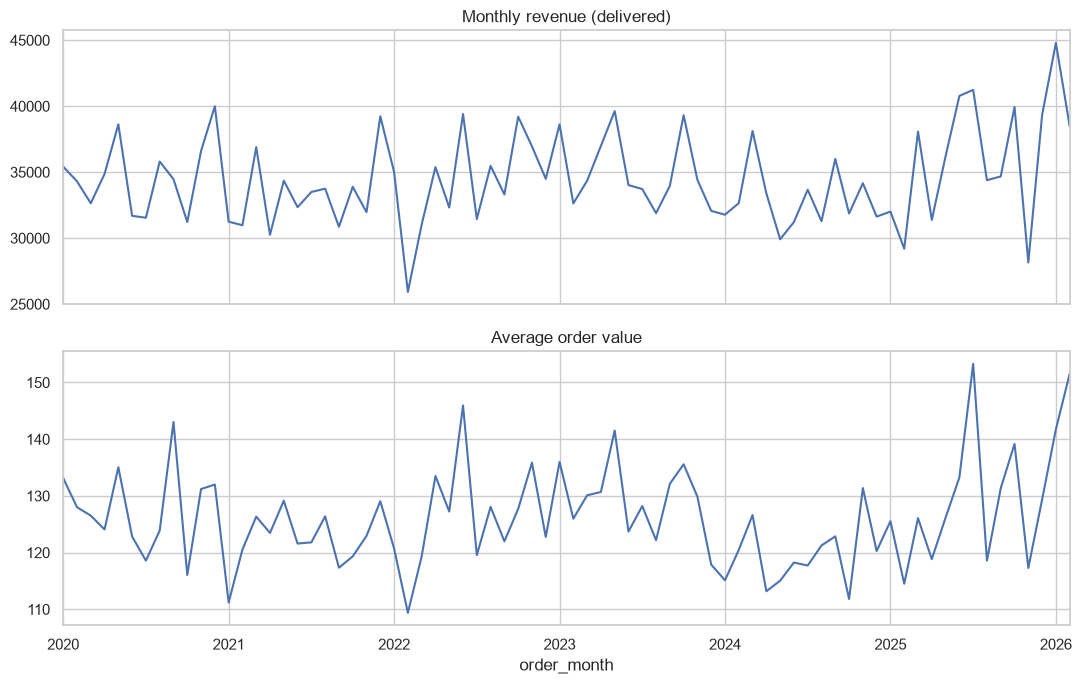

In [8]:
# %% 4. ANALYSIS 1 - Revenue performance (growth, drivers, seasonality)
last = orders_d.order_date.max()
month_complete = last == last + pd.offsets.MonthEnd(0)
print("Data ends:", last.date(), "| last month complete:", month_complete)

mon = (orders_d.groupby("order_month")
       .agg(orders=("order_id", "nunique"), revenue=("order_revenue", "sum"),
            customers=("customer_id", "nunique"), units=("quantity", "sum"))
       .assign(aov=lambda d: d.revenue / d.orders))
mon["mom"] = mon.revenue.pct_change()
mon["yoy"] = mon.revenue.pct_change(12)
mon_c = mon if month_complete else mon.iloc[:-1]        # drop a partial final month from trend and tests

# is there a real trend?
lr = stats.linregress(np.arange(len(mon_c)), mon_c.revenue)
log("Revenue", "Linear trend", "revenue ~ time", lr.slope, lr.pvalue, f"{lr.slope:,.0f} USD per month")

# growth decomposition on COMPLETE years only: volume effect vs basket-size effect
full = orders_d[orders_d.order_date.dt.year < last.year]
yr = full.groupby("year").agg(orders=("order_id", "nunique"), revenue=("order_revenue", "sum"))
yr["aov"] = yr.revenue / yr.orders
yr["volume_effect"] = (yr.orders - yr.orders.shift()) * yr.aov.shift()
yr["basket_effect"] = (yr.aov - yr.aov.shift()) * yr.orders
print(yr)
h, p = stats.kruskal(*[g.order_revenue.values for _, g in full.groupby("year")])
log("Revenue", "Kruskal-Wallis", "order value differs by year", h, p)

# current (partial) year vs the same dates last year: like for like
cy = orders_d[orders_d.order_date.dt.year == last.year]
py = orders_d[(orders_d.order_date.dt.year == last.year - 1) & (orders_d.order_date.dt.dayofyear <= last.dayofyear)]
ytd = pd.DataFrame({f"{last.year - 1} same period": [len(py), py.order_revenue.sum()],
                    f"{last.year} YTD": [len(cy), cy.order_revenue.sum()]}, index=["orders", "revenue"])
ytd["change_%"] = (ytd.iloc[:, 1] / ytd.iloc[:, 0] - 1) * 100
print(ytd)
u, p = stats.mannwhitneyu(py.order_revenue, cy.order_revenue)
log("Revenue", "Mann-Whitney U", f"order value {last.year} YTD vs same period {last.year - 1}", u, p,
    f"median {cy.order_revenue.median():.2f} vs {py.order_revenue.median():.2f}")
print(f"Mann-Whitney, order value {last.year} YTD vs {last.year - 1} same period: p = {p:.4f}",
      f"| medians {cy.order_revenue.median():.2f} vs {py.order_revenue.median():.2f}")

# seasonality on revenue PER DAY (otherwise February looks weak just because it is shorter), complete years only
sea = mon_c[mon_c.index.year < last.year].reset_index()
sea["rev_per_day"] = sea.revenue / sea.order_month.dt.days_in_month
sea["yr"], sea["mo"] = sea.order_month.dt.year, sea.order_month.dt.month
sea["idx"] = sea.rev_per_day / sea.groupby("yr").rev_per_day.transform("mean")
h, p = stats.kruskal(*[g.idx.values for _, g in sea.groupby("mo")])
log("Revenue", "Kruskal-Wallis", "daily-revenue seasonal index differs by calendar month", h, p)
print(sea.groupby("mo").idx.mean().round(3))

dow = orders_d.groupby("day_of_week").agg(orders=("order_id", "count"), revenue=("order_revenue", "sum"))
print(dow)
h, p = stats.kruskal(*[g.order_revenue.values for _, g in orders_d.groupby("day_of_week")])
log("Revenue", "Kruskal-Wallis", "order value differs by day of week", h, p)

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
mon_c.revenue.plot(ax=ax[0], title="Monthly revenue (delivered)")
mon_c.aov.plot(ax=ax[1], title="Average order value")
plt.tight_layout(); plt.show()

**What we found**
- **Revenue is flat.** About $417k in 2020 and $425k in 2025, with roughly 3,250 orders every year. The trend test (p = 0.15) finds no growth.
- Changes from year to year come mostly from **basket size** (AOV between $119 and $130), not from the number of orders. But even those AOV differences are not statistically clear (p = 0.09).
- **2026 so far** (to 30 March): orders +3.6% and revenue +17.7% against the same period of 2025. But the typical order value did not really change (p = 0.14), so a few large orders are behind the jump. Treat it as encouraging, not proven.
- **No seasonality** (p = 0.98) and **no day-of-week effect** (p = 0.76).

---
## Analysis 2. Churn and retention  (weight 15%)
**Business question:** *Which customers are leaving, why, and who is likely to leave next?*

**What this does:**
1. Compares churn rates across tier, channel, country, device and so on, using statistical tests.
2. Compares the numbers (orders, spend, reviews) of churned and active customers.
3. Builds a simple model that gives every customer a **churn risk score**. We build it twice: without and with `days_since_last_purchase`, then keep the better one.
4. Checks the model honestly using cross-validation (the score for each customer comes from a model that never saw that customer).

In [9]:
# %% 5. ANALYSIS 2 - Churn and retention drivers
def cat_vs_churn(df, col, target="churned"):
    ct = pd.crosstab(df[col], df[target])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    log("Churn", "Chi-square", f"{col} vs churned (Cramer's V={v:.3f})", chi2, p)
    return df.groupby(col)[target].agg(churn_rate="mean", customers="size").sort_values("churn_rate", ascending=False)

print("Overall churn:", customers.churned.mean().round(3))
for c in ["membership_tier", "acquisition_channel", "country", "preferred_category",
          "preferred_device", "preferred_payment_method", "gender", "newsletter_subscribed"]:
    print(f"\n{c}\n", cat_vs_churn(customers, c))

num_cols = ["age", "total_orders", "total_spend_usd", "avg_order_value_usd", "reviews_given",
            "avg_review_score", "returns_made", "wishlist_items"]
for c in num_cols:
    a = customers.loc[customers.churned == 1, c].dropna()
    b = customers.loc[customers.churned == 0, c].dropna()
    u, p = stats.mannwhitneyu(a, b)
    log("Churn", "Mann-Whitney U", f"{c}: churned median {a.median():.2f} vs active {b.median():.2f}", u, p)

# LEAKAGE CHECK: churn is probably defined from days_since_last_purchase, so it is excluded from the model
print(customers.groupby("churned").days_since_last_purchase.describe())

snapshot = orders_v.order_date.max() + pd.Timedelta(days=1)
# registration_date is unreliable (about 74% of orders predate it), so tenure is measured from the first order instead
first_ord = orders_v.groupby("customer_id").order_date.min()
customers["tenure_days"] = (snapshot - customers.customer_id.map(first_ord)).dt.days

cat_f = ["country", "gender", "membership_tier", "acquisition_channel", "preferred_category",
         "preferred_device", "preferred_payment_method"]
num_f = num_cols + ["newsletter_subscribed", "tenure_days"]
def make_pipe(nums):
    return Pipeline([
        ("prep", ColumnTransformer([
            ("c", OneHotEncoder(handle_unknown="ignore"), cat_f),
            ("n", Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), nums)])),
        ("m", LogisticRegression(max_iter=1000))])

pipe = make_pipe(num_f)
X, y = customers[cat_f + num_f], customers.churned
cv = StratifiedKFold(5, shuffle=True, random_state=42)
customers["churn_prob"] = cross_val_predict(pipe, X, y, cv=cv, method="predict_proba")[:, 1]   # out-of-fold
print("Cross-validated ROC-AUC:", round(roc_auc_score(y, customers.churn_prob), 3))

def top_decile_lift(prob):
    """churn rate among the 10% highest-risk customers divided by the overall churn rate"""
    return y[prob >= np.quantile(prob, .9)].mean() / y.mean()
print("Top-decile lift (base model):", round(top_decile_lift(customers.churn_prob), 2))

# sensitivity: does adding recency (days_since_last_purchase) change the picture?
num_f2 = num_f + ["days_since_last_purchase"]
p2 = cross_val_predict(make_pipe(num_f2), customers[cat_f + num_f2], y, cv=cv, method="predict_proba")[:, 1]
print("ROC-AUC with recency:", round(roc_auc_score(y, p2), 3), "| top-decile lift:", round(top_decile_lift(p2), 2))

# DECISION: score customers with the recency model (better ranking). Label it as "recency-driven churn risk".
customers["churn_prob_base"] = customers.churn_prob
customers["churn_prob"] = p2
print("Mean predicted churn:", round(customers.churn_prob.mean(), 3), "(should be close to the actual", round(y.mean(), 3), ")")

pipe = make_pipe(num_f2)
pipe.fit(customers[cat_f + num_f2], y)
names = pipe.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(pipe.named_steps["m"].coef_[0], index=names).sort_values()
print(pd.concat([coefs.head(8), coefs.tail(8)]))   # standardised effect on churn log-odds


Overall churn: 0.089

membership_tier
                  churn_rate  customers
membership_tier                       
Gold                   0.10       1177
Free                   0.10       4443
Platinum               0.08        644
Silver                 0.07       1736

acquisition_channel
                      churn_rate  customers
acquisition_channel                       
Referral                   0.10        473
Direct                     0.10        826
Social Media               0.09       1758
Email Campaign             0.09       1494
Paid Ad                    0.09       1255
Organic Search             0.08       2194

country
                 churn_rate  customers
country                              
Turkey                0.13         76
Poland                0.13        100
South Africa          0.13         94
Japan                 0.12        238
Germany               0.10        637
Spain                 0.10        152
Canada                0.10        409
United St

**What we found**
- Overall churn is **8.9%**.
- **Real differences** (after correcting for multiple tests): churned customers have **fewer orders** (median 7 vs 13), **lower spend** ($460 vs $883), **fewer reviews** (1 vs 2), and membership tier matters a little (Silver 7% vs Free/Gold 10%, a small effect).
- **No real difference** for channel, country, product category, device, payment method, gender or age. Small gaps in those tables (for example Turkey or Crypto payers) are most likely chance.
- **Model quality:** without recency the model barely beats guessing (ROC-AUC 0.59). With recency it improves to **0.65**, and the riskiest 10% of customers churn about **2.5 times** more than average. That is useful for ranking, not for precise prediction.
- The average predicted churn is 0.089, matching the true rate, so the scores are properly calibrated.
- Careful: orders and spend are lifetime totals, so someone who left early had less time to build them up. They go *with* churn, but they are not proven *causes*.

---
## Analysis 3. RFM groups and simple CLV  (weight 15%)
**Business question:** *Which customers deserve retention effort, and how much is each worth?*

**What this does:** uses the `orders` table to score every customer on **R**ecency, **F**requency and **M**onetary value (1 to 5 each), then names groups: Champions, Loyal, At Risk, Hibernating, and so on. It also makes a quick CLV estimate (expected orders x average order value x margin).

**Important:** this CLV is a simple extrapolation. The next cell (6b) tests whether it can be trusted.

In [10]:
# %% 6. ANALYSIS 3 - RFM segmentation and customer lifetime value
good = orders_d   # revenue and frequency count delivered orders only
rfm = good.groupby("customer_id").agg(first_order_date=("order_date", "min"), last_order_date=("order_date", "max"),
                                      frequency=("order_id", "nunique"), monetary=("order_revenue", "sum"))
rfm["recency"] = (snapshot - rfm.last_order_date).dt.days
rfm["r"] = pd.qcut(rfm.recency.rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["f"] = pd.qcut(rfm.frequency.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["m"] = pd.qcut(rfm.monetary.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["segment"] = np.select(
    [(rfm.r >= 4) & (rfm.f >= 4), (rfm.r >= 3) & (rfm.f >= 3), (rfm.r >= 4) & (rfm.f <= 2),
     (rfm.r <= 2) & (rfm.f >= 3), (rfm.r <= 2) & (rfm.f <= 2)],
    ["Champions", "Loyal", "New / Promising", "At Risk", "Hibernating"], default="Needs Attention")

# simple CLV: expected orders over next 12m x average order value x (1 - churn probability) x margin
life_days = (snapshot - rfm.first_order_date).dt.days.clip(lower=365)   # at least 1 year of exposure, so a brand-new customer is not extrapolated to a huge yearly rate
rfm["orders_per_year"] = rfm.frequency / life_days * 365
rfm["aov"] = rfm.monetary / rfm.frequency
rfm = rfm.join(customers.set_index("customer_id")[["churn_prob", "churned"]])
rfm["clv_12m"] = rfm.orders_per_year * rfm.aov * (1 - rfm.churn_prob) * MARGIN
rfm["clv_to_date"] = rfm.monetary * MARGIN

seg_tbl = rfm.groupby("segment").agg(customers=("monetary", "size"), revenue=("monetary", "sum"),
                                     avg_revenue=("monetary", "mean"), avg_clv_12m=("clv_12m", "mean"),
                                     avg_clv_to_date=("clv_to_date", "mean"),
                                     churn_prob_pct=("churn_prob", lambda x: x.mean() * 100),
                                     actual_churn_pct=("churned", lambda x: x.mean() * 100))
seg_tbl["revenue_share_pct"] = seg_tbl.revenue / seg_tbl.revenue.sum() * 100
print(seg_tbl.sort_values("revenue", ascending=False))

# do the order-based RFM segments line up with the churn flag from the customers table?
chi2, p, *_ = stats.chi2_contingency(pd.crosstab(rfm.segment, rfm.churned))
log("CLV", "Chi-square", "RFM segment vs churned flag", chi2, p)

# concentration: how much revenue comes from the top 20% of customers?
srt = rfm.monetary.sort_values(ascending=False)
print("Top 20% customers share of revenue:", round(srt.head(int(len(srt) * .2)).sum() / srt.sum(), 3))

# does tier matter for value?
tmp = customers.set_index("customer_id").join(rfm[["monetary"]], how="inner")
h, p = stats.kruskal(*[g.monetary.values for _, g in tmp.groupby("membership_tier")])
log("CLV", "Kruskal-Wallis", "customer revenue differs by membership tier", h, p)


                 customers    revenue  avg_revenue  avg_clv_12m  \
segment                                                           
Champions             1621 900,068.65       555.26        33.71   
Loyal                 1578 649,342.29       411.50        28.32   
At Risk               1241 492,364.16       396.75        21.40   
Hibernating           1719 298,019.01       173.37        11.51   
New / Promising        752 153,648.33       204.32        32.15   
Needs Attention        490  91,684.06       187.11        21.14   

                 avg_clv_to_date  churn_prob_pct  actual_churn_pct  \
segment                                                              
Champions                 166.58            9.04              8.45   
Loyal                     123.45            9.16              8.68   
At Risk                   119.02            8.99             10.07   
Hibernating                52.01            8.94              9.31   
New / Promising            61.30           

**What we found**
- The groups add up to **$2.585M**, which equals the `monthly_revenue` total. That is a good check.
- The top 20% of customers bring **48%** of revenue, so revenue is spread across the base, not concentrated in a few.
- Order revenue does **not** differ by membership tier (p = 0.94).
- The groups here do **not** line up with the churn flag (p = 0.40), because they come from different data (a sample of orders vs the full customer history).
- The CLV numbers in this table are rough. See 6b: they did not hold up.

---
## Analysis 3b. A properly tested CLV forecast
**Business question:** *How much will each customer spend in the next 12 months, and can we trust that prediction?*

**What this does:** a prediction is only useful if it works on data it has not seen. So:
1. **Hide the last 12 months** and predict them from the earlier history.
2. Compare three methods: a simple "same as before" guess, a standard purchase-timing model called **BG/NBD**, and a machine-learning model (gradient boosting).
3. Score each on: error size, whether it ranks customers correctly (Spearman), how much of next year's revenue the predicted top 20% really hold, and whether the total is right.
4. Use BG/NBD to forecast the **next** 3, 6 and 12 months.

**How to read the table:** if a method ranks customers no better than chance, "top 20% capture" will be about 0.20. A perfect ranking would score 0.89.

In [11]:
# %% 6b. Forward-looking CLV: a validated forecast of the next 12 months (BG/NBD + gradient-boosting benchmark)
# Why: clv_12m in cell 6 is a simple extrapolation and was never tested. Here we hide the most recent 12 months,
# predict them from the earlier history, and measure how close each method gets before trusting any forecast.
from scipy.optimize import minimize
from scipy.special import gammaln, hyp2f1
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import KFold

YEAR = 365.25

def bgnbd_prep(df, cutoff):
    """One row per customer using only purchases before `cutoff`.
    x = repeat purchase days, t_x = first-to-last purchase (years), T = first purchase to cutoff (years)."""
    d = df[df.order_date < cutoff]
    days = d.groupby(["customer_id", d.order_date.dt.normalize()]).order_revenue.sum().reset_index()
    g = days.groupby("customer_id")
    first, lastp = g.order_date.min(), g.order_date.max()
    return pd.DataFrame({"x": g.size() - 1, "t_x": (lastp - first).dt.days / YEAR,
                         "T": (cutoff - first).dt.days / YEAR,
                         "monetary": g.order_revenue.sum(), "n_days": g.size()})

def bgnbd_nll(params, x, t_x, T):
    r, alpha, a, b = params
    ll1 = gammaln(r + x) - gammaln(r) + r * np.log(alpha)
    ll2 = gammaln(a + b) + gammaln(b + x) - gammaln(b) - gammaln(a + b + x)
    ln_a3 = -(r + x) * np.log(alpha + T)
    ln_a4 = np.log(a) - np.log(b + np.maximum(x, 1) - 1) - (r + x) * np.log(alpha + t_x)
    return -(ll1 + ll2 + np.where(x > 0, np.logaddexp(ln_a3, ln_a4), ln_a3)).sum()

def fit_bgnbd(x, t_x, T):
    res = minimize(bgnbd_nll, x0=[1.0, 5.0, 2.0, 2.0], args=(x, t_x, T), method="L-BFGS-B",
                   bounds=[(1e-3, 100), (1e-3, 1000), (1.0001, 100), (1e-3, 100)])
    return res.x

def bgnbd_expected(params, t, x, t_x, T):
    """Expected number of purchases in the next t years."""
    r, alpha, a, b = params
    z = t / (alpha + T + t)
    first = (a + b + x - 1) / (a - 1)
    second = 1 - ((alpha + T) / (alpha + T + t)) ** (r + x) * hyp2f1(r + x, b + x, a + b + x - 1, z)
    denom = 1 + (x > 0) * (a / (b + np.maximum(x, 1) - 1)) * ((alpha + T) / (alpha + t_x)) ** (r + x)
    return first * second / denom

def bgnbd_alive(params, x, t_x, T):
    r, alpha, a, b = params
    return 1 / (1 + (x > 0) * (a / (b + np.maximum(x, 1) - 1)) * ((alpha + T) / (alpha + t_x)) ** (r + x))

def shrunk_value(feat, k=3):
    """Average revenue per purchase day, pulled toward the overall average when a customer has few purchases."""
    g = feat.monetary.sum() / feat.n_days.sum()
    return (feat.monetary + k * g) / (feat.n_days + k)

# ---- 1. Validation: predict the last 12 months from everything before ----
cutoff = last - pd.Timedelta(days=365)
cal = bgnbd_prep(orders_d, cutoff)
future = orders_d[orders_d.order_date >= cutoff].groupby("customer_id").order_revenue.sum()
cal["actual_rev"] = cal.index.to_series().map(future).fillna(0)
h = (last - cutoff).days / YEAR

pars = fit_bgnbd(cal.x.values, cal.t_x.values, cal["T"].values)
print("BG/NBD parameters (r, alpha, a, b):", pars.round(3))

cal["pred_rev_naive"] = cal.monetary / cal["T"].clip(lower=1)           # "they will spend what they averaged per year"
cal["pred_rev_bgnbd"] = bgnbd_expected(pars, h, cal.x.values, cal.t_x.values, cal["T"].values) * shrunk_value(cal)

Xml = pd.DataFrame({"x": cal.x, "t_x": cal.t_x, "T": cal["T"], "recency": cal["T"] - cal.t_x,
                    "monetary": cal.monetary, "n_days": cal.n_days, "avg_value": cal.monetary / cal.n_days})
gbr = GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=42)
cal["pred_rev_ml"] = cross_val_predict(gbr, Xml, cal.actual_rev, cv=KFold(5, shuffle=True, random_state=42))

def score(pred):
    y_ = cal.actual_rev
    top = cal.loc[pred >= pred.quantile(.8), "actual_rev"].sum() / y_.sum()
    return {"MAE": (pred - y_).abs().mean(), "RMSE": np.sqrt(((pred - y_) ** 2).mean()),
            "Spearman": stats.spearmanr(pred, y_)[0], "Top20%_capture": top, "Predicted/Actual total": pred.sum() / y_.sum()}

models = {"Naive (past yearly average)": "pred_rev_naive", "BG/NBD + shrunk value": "pred_rev_bgnbd", "Gradient boosting": "pred_rev_ml"}
res = pd.DataFrame({m: score(cal[c]) for m, c in models.items()}).T
print(res)
best_possible = cal.actual_rev.nlargest(int(len(cal) * .2)).sum() / cal.actual_rev.sum()
print(f"Top-20% capture if we ranked perfectly: {best_possible:.3f} | customers scored: {len(cal):,}")

# ---- 2. Forecast the NEXT 12 months with BG/NBD, using all history ----
cutoff_f = last + pd.Timedelta(days=1)
full = bgnbd_prep(orders_d, cutoff_f)
pf = fit_bgnbd(full.x.values, full.t_x.values, full["T"].values)
for mths in (3, 6, 12):
    full[f"pred_orders_{mths}m"] = bgnbd_expected(pf, mths / 12, full.x.values, full.t_x.values, full["T"].values)
full["p_alive"] = bgnbd_alive(pf, full.x.values, full.t_x.values, full["T"].values)
full["pred_revenue_12m"] = full.pred_orders_12m * shrunk_value(full)
full["clv_12m_model"] = full.pred_revenue_12m * MARGIN

rfm["clv_12m_heuristic"] = rfm.clv_12m
rfm = rfm.join(full[["pred_orders_3m", "pred_orders_6m", "pred_orders_12m", "p_alive", "pred_revenue_12m", "clv_12m_model"]])
rfm["clv_12m"] = rfm.clv_12m_model.fillna(rfm.clv_12m_heuristic)       # model-based value replaces the heuristic

print(rfm.groupby("segment").agg(customers=("clv_12m", "size"), pred_orders_12m=("pred_orders_12m", "mean"),
                                 p_alive=("p_alive", "mean"), pred_revenue_12m=("pred_revenue_12m", "mean"),
                                 clv_12m=("clv_12m", "mean")).sort_values("clv_12m", ascending=False))
print(f"Total expected revenue, next 12 months from existing customers: {rfm.pred_revenue_12m.sum():,.0f}",
      f"| last 12 months actual (all customers): {future.sum():,.0f}")
print(f"  of which from customers whose first order was inside the last 12 months: {future[~future.index.isin(cal.index)].sum():,.0f}")
print("Spearman test (best model vs actual):", stats.spearmanr(cal.pred_rev_bgnbd, cal.actual_rev))


BG/NBD parameters (r, alpha, a, b): [30.715 72.782  2.392 97.066]
                               MAE   RMSE  Spearman  Top20%_capture  \
Naive (past yearly average) 108.29 170.80      0.01            0.20   
BG/NBD + shrunk value        74.70 137.19      0.02            0.21   
Gradient boosting            76.79 137.26     -0.01            0.20   

                             Predicted/Actual total  
Naive (past yearly average)                    1.75  
BG/NBD + shrunk value                          0.93  
Gradient boosting                              1.00  
Top-20% capture if we ranked perfectly: 0.890 | customers scored: 7,044
                 customers  pred_orders_12m  p_alive  pred_revenue_12m  \
segment                                                                  
Champions             1621             0.42     0.98             53.39   
New / Promising        752             0.41     0.99             52.24   
Loyal                 1578             0.41     0.97             

**What we found**
- **It cannot pick winners.** All three methods score about 0.20 on top-20% capture, which is no better than random, and the ranking score is essentially zero (p = 0.13). In this order data, past purchases do not tell us which customer will spend next year.
- The fitted model explains why: almost all customers behave alike, buying roughly **0.42 orders a year**, with very few dropping out.
- **It does work for the total.** BG/NBD predicts 93% of the real total, while the simple guess overshoots by 75%.
- **Planning number:** existing customers should bring in about **$379k** over the next 12 months. Last year's existing customers brought in about $385k, and new customers added about $59k.
- So earlier ideas such as "Champions are worth $34 and Hibernating $11" are **not supported**. Every group is worth about $15 to $16 in expected margin.

---
## Analysis 3c. RFM groups from the customers table
**Business question:** *Which customers are our most valuable, which are slipping away, and does the grouping really match who churns?*

**Why again?** The `orders` table is a thin slice of history. The `customers` table has the full picture (days since last purchase, total orders, total spend). So here the RFM groups are rebuilt from it.

**What this does:** scores each customer, names the groups, and then tests whether the groups really differ in churn. Note: recency and the churn flag are measured at the same moment, so this shows a **link**, not a prediction.

In [12]:
# %% 6c. RFM from the customers table (full purchase history) and validation against the churn flag
# The order table holds only a slice of each customer's history (about 19% of the orders the customers table reports),
# so order-based RFM is thin. The customers table has recency, frequency and spend for the whole history.
customers["rfm_r"] = pd.qcut(customers.days_since_last_purchase.rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
customers["rfm_f"] = pd.qcut(customers.total_orders.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
customers["rfm_m"] = pd.qcut(customers.total_spend_usd.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
r_, f_ = customers.rfm_r, customers.rfm_f
customers["rfm_segment"] = np.select(
    [(r_ >= 4) & (f_ >= 4), (r_ >= 3) & (f_ >= 3), (r_ >= 4) & (f_ <= 2), (r_ <= 2) & (f_ >= 3), (r_ <= 2) & (f_ <= 2)],
    ["Champions", "Loyal", "New / Promising", "At Risk", "Hibernating"], default="Needs Attention")
customers["lifetime_margin_to_date"] = customers.total_spend_usd * MARGIN

seg_c = customers.groupby("rfm_segment").agg(
    customers=("customer_id", "size"), total_spend=("total_spend_usd", "sum"), avg_spend=("total_spend_usd", "mean"),
    avg_orders=("total_orders", "mean"), avg_days_since=("days_since_last_purchase", "mean"),
    churn_pct=("churned", lambda x: x.mean() * 100))
seg_c["spend_share_pct"] = seg_c.total_spend / seg_c.total_spend.sum() * 100
print(seg_c.sort_values("total_spend", ascending=False))

chi2, p, *_ = stats.chi2_contingency(pd.crosstab(customers.rfm_segment, customers.churned))
log("CLV", "Chi-square", "customers-table RFM segment vs churned flag", chi2, p)
srt = customers.total_spend_usd.sort_values(ascending=False)
print("Top 20% customers share of lifetime spend:", round(srt.head(int(len(srt) * .2)).sum() / srt.sum(), 3))
h, p = stats.kruskal(*[g.total_spend_usd.values for _, g in customers.groupby("membership_tier")])
log("CLV", "Kruskal-Wallis", "customers-table lifetime spend differs by membership tier", h, p)
# Note: recency and the churn flag are measured at the same moment, so this shows association, not prediction.


                 customers  total_spend  avg_spend  avg_orders  \
rfm_segment                                                      
At Risk               1919 4,376,269.51   2,280.49       24.37   
Champions             1293 3,722,437.39   2,878.92       30.95   
Loyal                 1588 2,992,046.93   1,884.16       19.52   
Hibernating           1281   563,423.63     439.83        4.52   
New / Promising       1277   557,061.02     436.23        4.62   
Needs Attention        642   257,900.32     401.71        4.50   

                 avg_days_since  churn_pct  spend_share_pct  
rfm_segment                                                  
At Risk                  115.38       8.49            35.10  
Champions                 12.88       4.56            29.85  
Loyal                     30.13       5.35            24.00  
Hibernating              114.76      15.69             4.52  
New / Promising           13.23      10.49             4.47  
Needs Attention           41.83      

**What we found**
| Group | Customers | Share of lifetime spend | Churn |
|---|---|---|---|
| Champions | 1,293 | 30% | 4.6% |
| Loyal | 1,588 | 24% | 5.4% |
| **At Risk** | 1,919 | **35%** | 8.5% |
| Hibernating | 1,281 | 4.5% | **15.7%** |
| New / Promising | 1,277 | 4.5% | 10.5% |
| Needs Attention | 642 | 2.1% | 11.4% |

- The groups really do separate churn (p is close to 0).
- **At Risk is the biggest prize.** These customers average 24 orders and about $2,280 of spend, but have not bought for about 115 days.
- Frequency protects: At Risk and Hibernating customers have the same recency (about 115 days), yet churn is 8.5% against 15.7%.
- The top 20% of customers hold **61%** of lifetime spend.
- Lifetime spend does differ by membership tier here (p is close to 0), even though the order sample did not show it.
- **Action:** test a win-back offer on a part of the At Risk group and keep a comparison group, so the real effect is measured.

---
## Analysis 4. Acquisition channel quality  (weight 10%)
**Business question:** *Which marketing channel brings the most valuable, longest-staying customers, so where should the budget go?*

**What this does:** compares each channel on number of customers, churn, average spend, orders and order value, then tests whether the spend differences are real.

In [13]:
# %% 7. ANALYSIS 4 - Acquisition channel quality
ch = customers.groupby("acquisition_channel").agg(
    customers=("customer_id", "count"), churn_rate=("churned", "mean"),
    avg_spend=("total_spend_usd", "mean"), avg_orders=("total_orders", "mean"),
    avg_aov=("avg_order_value_usd", "mean"), returns_per_order=("returns_made", "sum"),
    orders_sum=("total_orders", "sum"))
ch["return_rate"] = ch.returns_per_order / ch.orders_sum
print(ch.drop(columns=["returns_per_order", "orders_sum"]).sort_values("avg_spend", ascending=False))
h, p = stats.kruskal(*[g.total_spend_usd.values for _, g in customers.groupby("acquisition_channel")])
log("Channel", "Kruskal-Wallis", "total spend differs by channel", h, p)
# No acquisition cost column exists, so this is value/retention quality, not ROI. Add CAC in Power BI as a what-if.



                     customers  churn_rate  avg_spend  avg_orders  avg_aov  \
acquisition_channel                                                          
Direct                     826        0.10   1,653.55       16.87    94.61   
Paid Ad                   1255        0.09   1,633.15       17.07    95.06   
Email Campaign            1494        0.09   1,578.54       16.90    94.43   
Referral                   473        0.10   1,577.25       16.28    96.42   
Organic Search            2194        0.08   1,542.72       16.36    95.36   
Social Media              1758        0.09   1,458.82       16.01    94.09   

                     return_rate  
acquisition_channel               
Direct                      0.05  
Paid Ad                     0.05  
Email Campaign              0.05  
Referral                    0.05  
Organic Search              0.05  
Social Media                0.05  


**What we found**
- Average spend per customer ranges from $1,459 (Social Media) to $1,654 (Direct), but the difference is **not statistically real** (p = 0.46). Order value, churn and returns are also nearly the same.
- **No channel is proven better**, so this data gives no reason to move budget between channels.
- There is no acquisition cost in the data, so we cannot judge return on spend.
- The 5% return rate in this table comes from the `customers` table. The order-based figure is about 9%. They are measured differently, so do not compare them.

---
## Analysis 5. Discount effectiveness  (weight 10%)
**Business question:** *Do discounts bring extra sales, or do we just give margin away?*

**What this does:**
- Groups orders by discount level and compares units per order, order value, returns and ratings.
- Adds up the total cost of discounts.
- Tests whether bigger discounts mean bigger quantities or more returns.
- Checks whether customers whose **first** order was discounted are more or less loyal.

In [14]:
# %% 8. ANALYSIS 5 - Discount effectiveness
d = orders_v.groupby("discount_band").agg(
    orders=("order_id", "count"), avg_qty=("quantity", "mean"), aov=("order_revenue", "mean"),
    return_rate=("is_returned", "mean"), avg_rating=("customer_rating", "mean"),
    revenue=("order_revenue", "sum"), discount_cost=("discount_amount_usd", "sum"))
print(d)
print("Total discount given:", orders_v.discount_amount_usd.sum().round(0),
      "| as % of gross sales:", round(orders_v.discount_amount_usd.sum() / orders_v.subtotal_usd.sum() * 100, 2))

rho, p = stats.spearmanr(orders_v.discount_pct, orders_v.quantity)
log("Discount", "Spearman", "discount % vs quantity", rho, p)
rho, p = stats.spearmanr(orders_v.discount_pct, orders_v.is_returned)
log("Discount", "Spearman", "discount % vs returned", rho, p)

# does a discounted first order create a more or less loyal customer?
first = (orders_v.sort_values("order_date").drop_duplicates("customer_id")[["customer_id", "discount_pct"]]
         .assign(first_discounted=lambda x: (x.discount_pct > 0).astype(int)))
fc = customers.merge(first, on="customer_id")
print(fc.groupby("first_discounted").agg(customers=("customer_id", "count"), churn=("churned", "mean"),
                                         orders=("total_orders", "mean")))
chi2, p, *_ = stats.chi2_contingency(pd.crosstab(fc.first_discounted, fc.churned))
log("Discount", "Chi-square", "first-order discount vs churn", chi2, p)


               orders  avg_qty    aov  return_rate  avg_rating      revenue  \
discount_band                                                                 
0%              15300     1.70 133.21         0.09        4.00 2,038,046.99   
1-10%            3689     1.70 126.07         0.09        4.00   465,073.46   
11-20%           2897     1.69 108.37         0.09        4.01   313,951.26   
21-30%           1127     1.65  92.74         0.07        4.03   104,516.81   
31-50%            531     1.69  70.44         0.09        3.95    37,405.89   

               discount_cost  
discount_band                 
0%                      0.00  
1-10%              34,458.32  
11-20%             56,528.04  
21-30%             33,919.73  
31-50%             24,415.64  
Total discount given: 149322.0 | as % of gross sales: 5.45
                  customers  churn  orders
first_discounted                          
0                      4919   0.08   16.75
1                      2668   0.10   16.3

**What we found**
- Discounts cost **$149k, which is 5.45% of gross sales**, and 35% of orders carry one.
- **No sign they work:** units per order stay flat (about 1.7) at every discount level (p = 0.26), and returns and ratings do not change.
- **Deep discounts are the costly part.** Cost per discounted order is about $9 (1-10%), $20 (11-20%), $30 (21-30%) and $46 (31-50%). Orders above 20% off are 7% of orders but 39% of discount cost.
- First-order discounts: churn is 10% against 8%. After correcting for multiple tests this is borderline (adjusted p = 0.05), so call it "suggestive" only.
- **Caution:** this data cannot show whether discounts bring extra *visitors or orders*. A controlled test (some customers get the offer, some do not) would answer that.

---
## Analysis 6. Returns  (weight 10%)
**Business question:** *Which categories and products drive returns, and what do they cost?*

**What this does:** compares return rates by category, tests whether they differ, and runs a model that checks whether discount, delivery time, price, quantity, device or category predict a return.

In [15]:
# %% 9. ANALYSIS 6 - Returns
rc = orders_v.groupby("category").agg(orders=("order_id", "count"), return_rate=("is_returned", "mean"),
                                      returned_revenue=("order_revenue", lambda s: s[orders_v.loc[s.index, "is_returned"] == 1].sum()))
print(rc.sort_values("return_rate", ascending=False))
chi2, p, *_ = stats.chi2_contingency(pd.crosstab(orders_v.category, orders_v.is_returned))
log("Returns", "Chi-square", "return rate differs by category", chi2, p)

mdl = smf.logit("is_returned ~ discount_pct + delivery_days + np.log1p(unit_price_usd) + quantity"
                " + C(device_used) + C(category)", data=orders_v).fit(disp=0)
orr = pd.DataFrame({"odds_ratio": np.exp(mdl.params), "p": mdl.pvalues}).round(4)
print(orr.sort_values("p").head(12))


                        orders  return_rate  returned_revenue
category                                                     
Travel & Luggage           484         0.10          7,768.42
Pet Supplies               710         0.10          3,965.36
Home & Kitchen            2887         0.09         40,545.67
Food & Grocery            1393         0.09          4,766.52
Toys & Games              1440         0.09          9,404.54
Books                     1848         0.09          7,429.22
Automotive                 720         0.09          6,447.37
Electronics               4256         0.09         91,151.50
Health & Wellness         1141         0.09          5,165.45
Office Supplies            732         0.08         12,686.22
Jewelry & Accessories      911         0.08         12,205.07
Sports & Outdoors         1674         0.08         12,238.71
Beauty & Personal Care    1600         0.08          8,378.58
Clothing & Apparel        3748         0.08         31,556.40
        

**What we found**
- Return rates are **8% to 10% in every category** (p = 0.72). No category is a problem.
- None of the other factors (discount, delivery days, price, device) predicts returns. The smallest p-value in the model is 0.22.
- Returned orders are worth about **$254k**. Electronics ($91k), Home & Kitchen ($41k) and Clothing ($32k) are about 64% of that, simply because they are large.
- **Action:** returns are a company-wide issue, not a category issue.

---
## Analysis 7. Product and category performance  (weight 8%)
**Business question:** *Which products carry the business, and which should be promoted, fixed or dropped?*

**What this does:**
- Ranks products by revenue and labels them **A** (the products making the first 80% of revenue), **B** (next 15%) and **C** (last 5%).
- Splits products by rating and return rate into four boxes. *Because this uses the median, half the products always land in each half, so we then test whether the differences are real.*
- Prints the **test table** with every test so far and its corrected (adjusted) p-value.

In [16]:
# %% 10. ANALYSIS 7 - Product and category performance (Pareto + quadrant)
pr = orders_v.groupby(["category", "product_name", "product_key"]).agg(
    orders=("order_id", "count"), revenue=("order_revenue", "sum"), avg_rating=("customer_rating", "mean"),
    return_rate=("is_returned", "mean"), avg_discount=("discount_pct", "mean")).reset_index()
pr = pr.sort_values("revenue", ascending=False)
pr["cum_share"] = pr.revenue.cumsum() / pr.revenue.sum()
pr["abc_class"] = np.select([pr.cum_share <= .80, pr.cum_share <= .95], ["A", "B"], default="C")
pr["quadrant"] = np.select(
    [(pr.avg_rating >= pr.avg_rating.median()) & (pr.return_rate <= pr.return_rate.median()),
     (pr.avg_rating >= pr.avg_rating.median())],
    ["Stars (high rating, low returns)", "Good but returned"],
    default="Problem (low rating)")
print(pr.abc_class.value_counts(), "\n", pr.quadrant.value_counts())
# the quadrant uses median splits, so about half of all products always land in each half: check the differences are real
d_ = orders_v.dropna(subset=["customer_rating"])
h, p = stats.kruskal(*[g.customer_rating.values for _, g in d_.groupby("product_key") if len(g) > 1])
log("Products", "Kruskal-Wallis", "customer rating differs by product", h, p)
chi2, p, *_ = stats.chi2_contingency(pd.crosstab(orders_v.product_key, orders_v.is_returned))
log("Products", "Chi-square", "return rate differs by product", chi2, p)
print(pr[["avg_rating", "return_rate"]].describe())

pd.set_option("display.max_colwidth", 70)
print(test_table()[["analysis", "detail", "p_value", "p_adj_BH", "significant_adj"]].to_string())


abc_class
A    62
B    48
C    30
Name: count, dtype: int64 
 quadrant
Problem (low rating)                70
Stars (high rating, low returns)    35
Good but returned                   35
Name: count, dtype: int64
       avg_rating  return_rate
count      140.00       140.00
mean         4.00         0.09
std          0.10         0.02
min          3.60         0.03
25%          3.96         0.07
50%          4.01         0.08
75%          4.05         0.10
max          4.23         0.17
        analysis                                                     detail  p_value  p_adj_BH  significant_adj
0   Data quality                      registration_date vs first order date     0.57      0.57            False
1        Revenue                                             revenue ~ time     0.15      0.24            False
2        Revenue                                order value differs by year     0.09      0.24            False
3        Revenue                   order value 2026 YTD vs 

**What we found**
- Of 140 products, **62 are class A** (make 80% of revenue), 48 are B and 30 are C. Moderate concentration.
- Product ratings run from 3.6 to 4.2 and return rates from 3% to 17%, but these differences are **not real** (rating p = 0.22, returns p = 0.80). With so few ratings per product, this is just chance.
- So the "Problem / Stars" boxes are **not meaningful** and are left out of the Power BI export. Keep the A/B/C ranking, which is simply a revenue ranking.

**Reading the test table**
Look at the last two columns. `significant_adj = True` means the difference is real even after correcting for running many tests. Only a handful are True (the churn-related ones and the customers-table RFM and tier tests). Everything else is a tested "no difference".

---
## Analysis 8. Delivery and customer experience  (weight 5%)
**Business question:** *Does slow delivery hurt ratings or increase returns, and what delivery promise should we make?*

**What this does:** groups orders by delivery time (0-2, 3-4, 5-6, 7+ days) and compares ratings and returns. It also tests the link between delivery days and rating.

In [17]:
# %% 11. ANALYSIS 8 - Delivery and customer experience
rho, p = stats.spearmanr(orders_v.dropna(subset=["customer_rating"]).delivery_days,
                         orders_v.dropna(subset=["customer_rating"]).customer_rating)
log("Delivery", "Spearman", "delivery days vs rating", rho, p)
print(orders_v.groupby("delivery_band").agg(orders=("order_id", "count"), rating=("customer_rating", "mean"),
                                            return_rate=("is_returned", "mean")))
h, p = stats.kruskal(*[g.customer_rating.dropna().values for _, g in orders_v.groupby("delivery_band")])
log("Delivery", "Kruskal-Wallis", "rating differs by delivery band", h, p)


               orders  rating  return_rate
delivery_band                             
0-2 days         5418    3.99         0.09
3-4 days        10491    4.01         0.09
5-6 days         3515    4.00         0.08
7+ days          4120    4.00         0.08


**What we found**
- Ratings are about 4.0 in every delivery group, and return rates are 8% to 9% (p = 0.79).
- Even the 17% of orders that take 7+ days are rated the same.
- **No evidence that faster delivery would raise satisfaction or cut returns.**

---
## Analysis 9. Browsing behaviour, device and payment  (weight 3%)
**Business question:** *Do longer visits or more pages mean bigger orders? Is any device or payment method worth optimising?*

**What this does:** tests whether session time and pages viewed relate to order value, and compares order value and returns by device and by payment method.

In [18]:
# %% 12. ANALYSIS 9 - Behaviour, device and payment
for c in ["session_duration_minutes", "pages_viewed_before_purchase"]:
    rho, p = stats.spearmanr(orders_v[c], orders_v.order_revenue)
    log("Behaviour", "Spearman", f"{c} vs order value", rho, p)
print(orders_v.groupby("device_used").agg(orders=("order_id", "count"), aov=("order_revenue", "mean"),
                                          return_rate=("is_returned", "mean"), session=("session_duration_minutes", "mean")))
print(orders_v.groupby("payment_method").agg(orders=("order_id", "count"), aov=("order_revenue", "mean"),
                                             return_rate=("is_returned", "mean")))
h, p = stats.kruskal(*[g.order_revenue.values for _, g in orders_v.groupby("device_used")])
log("Behaviour", "Kruskal-Wallis", "order value differs by device", h, p)
h, p = stats.kruskal(*[g.order_revenue.values for _, g in orders_v.groupby("payment_method")])
log("Behaviour", "Kruskal-Wallis", "order value differs by payment method", h, p)

             orders    aov  return_rate  session
device_used                                     
Desktop        7615 126.91         0.09    16.75
Mobile        13187 124.81         0.09    16.75
Tablet         2742 126.43         0.08    17.10
                      orders    aov  return_rate
payment_method                                  
Bank Transfer            869 117.43         0.07
Buy Now Pay Later       1411 124.43         0.09
Credit Card             8953 125.99         0.09
Cryptocurrency           468 136.29         0.10
Debit Card              5169 126.47         0.08
PayPal                  4270 124.83         0.09
UPI / Digital Wallet    2404 126.00         0.09


**What we found**
- Session time and pages viewed have **no link** with order value.
- Order value is about $125 to $127 on desktop, mobile and tablet (p = 0.66).
- By payment method, Crypto looks highest ($136) and Bank Transfer lowest ($117), but the difference is **not real** (p = 0.66).

---
## Analysis 10. Demographics and geography  (weight 3%)
**Business question:** *Which age groups and countries are most valuable, and where should we focus?*

**What this does:** compares average spend and churn by age band, gender and country, with a test for each.

In [19]:
# %% 13. ANALYSIS 10 - Demographics and geography
customers["age_band"] = pd.cut(customers.age, [0, 24, 34, 44, 54, 64, 120],
                               labels=["<25", "25-34", "35-44", "45-54", "55-64", "65+"])
for c in ["age_band", "gender", "country"]:
    print(customers.groupby(c).agg(customers=("customer_id", "count"), avg_spend=("total_spend_usd", "mean"),
                                   churn=("churned", "mean")).round(3), "\n")
    h, p = stats.kruskal(*[g.total_spend_usd.values for _, g in customers.groupby(c, observed=True)])
    log("Demographics", "Kruskal-Wallis", f"spend differs by {c}", h, p)


          customers  avg_spend  churn
age_band                             
<25            1477   1,540.01   0.10
25-34          2346   1,565.16   0.09
35-44          2424   1,567.69   0.08
45-54          1320   1,558.86   0.10
55-64           379   1,586.30   0.09
65+              54   1,179.41   0.06 

        customers  avg_spend  churn
gender                             
Female       3895   1,538.69   0.09
Male         3866   1,574.04   0.09
Other         239   1,634.74   0.09 

                customers  avg_spend  churn
country                                    
Australia             323   1,606.13   0.08
Brazil                370   1,534.59   0.06
Canada                409   1,428.97   0.10
France                483   1,639.92   0.09
Germany               637   1,444.13   0.10
India                 711   1,665.53   0.07
Italy                 167   1,415.47   0.05
Japan                 238   1,816.22   0.12
Mexico                288   1,590.53   0.08
Netherlands           153   

**What we found**
- Average spend is about $1,540 to $1,590 for almost every age band and gender. The 65+ band looks lower, but it has only 54 customers.
- Country results (for example Japan $1,816, Sweden $1,226) are based on small groups and are **not real** differences (p = 0.77).
- **None of age, gender or country predicts spend.**

---
## Analysis 11. Revenue forecast  (weight 6%)
**Business question:** *What revenue should we plan for over the next 6 months, and how reliable is that number?*

**What this does:** tries four forecasting approaches by hiding the last 6 months and seeing which one predicts them best:
1. Trend + seasonality
2. Seasonality only
3. A flat level (no trend, no seasons)
4. A naive benchmark (average of the previous 12 months)

It then uses the best model to forecast the next 6 months, with a range (lower to upper).

*Error is shown as MAPE: the average percentage miss. Lower is better.*

In [20]:
# %% 14. ANALYSIS 11 - Revenue forecast: compare simple models on a hold-out, then forecast 6 months
# Seasonality and trend tested as flat in cell 4, so a flat model may win; let the hold-out decide.
ts = mon_c.revenue.asfreq("MS")          # complete months only (cell 4 dropped a partial final month)
train, test = ts.iloc[:-6], ts.iloc[-6:]

configs = {"Trend + seasonality": dict(trend="add", seasonal="add", seasonal_periods=12),
           "Seasonality only": dict(trend=None, seasonal="add", seasonal_periods=12),
           "Flat level (no trend, no seasonality)": dict(trend=None, seasonal=None)}
rows = {}
for name, cfg in configs.items():
    fit = ExponentialSmoothing(train, **cfg).fit()
    rows[name] = (abs(test - fit.forecast(6)) / test).mean()
naive = (abs(test - train.iloc[-12:].mean()) / test).mean()
mape_tbl = pd.Series(rows, name="hold-out MAPE")
print((mape_tbl * 100).round(1).astype(str) + "%")
print(f"Naive benchmark (mean of previous 12 months): {naive:.1%}")

best = mape_tbl.idxmin()
print("Chosen model:", best)
final = ExponentialSmoothing(ts, **configs[best]).fit()
fc_ = final.forecast(6)
sd = (ts - final.fittedvalues).std()
forecast = pd.DataFrame({"month_start": ts.index.append(fc_.index),
                         "actual": list(ts.values) + [np.nan] * 6,
                         "forecast": [np.nan] * len(ts) + list(fc_.values)})
forecast["lower"] = forecast.forecast - 1.96 * sd
forecast["upper"] = forecast.forecast + 1.96 * sd
forecast["model"] = best
forecast["model_mape"] = mape_tbl[best]
print(forecast.tail(6).round(0))

Trend + seasonality                      15.0%
Seasonality only                         15.2%
Flat level (no trend, no seasonality)    14.1%
Name: hold-out MAPE, dtype: str
Naive benchmark (mean of previous 12 months): 13.4%
Chosen model: Flat level (no trend, no seasonality)
   month_start  actual  forecast     lower     upper  \
74  2026-03-01     NaN 34,490.00 27,718.00 41,262.00   
75  2026-04-01     NaN 34,490.00 27,718.00 41,262.00   
76  2026-05-01     NaN 34,490.00 27,718.00 41,262.00   
77  2026-06-01     NaN 34,490.00 27,718.00 41,262.00   
78  2026-07-01     NaN 34,490.00 27,718.00 41,262.00   
79  2026-08-01     NaN 34,490.00 27,718.00 41,262.00   

                                    model  model_mape  
74  Flat level (no trend, no seasonality)        0.00  
75  Flat level (no trend, no seasonality)        0.00  
76  Flat level (no trend, no seasonality)        0.00  
77  Flat level (no trend, no seasonality)        0.00  
78  Flat level (no trend, no seasonality)        0

**What we found**
| Model | Average miss (MAPE) |
|---|---|
| Naive: average of previous 12 months | **13.4%** |
| Flat level (chosen) | 14.1% |
| Trend + seasonality | 15.0% |
| Seasonality only | 15.2% |

- The simplest approach wins, which agrees with the earlier finding of no trend and no seasonality.
- **Planning number: about $34,500 a month**, with a 95% range of roughly $27,700 to $41,300.
- The `model_mape` column looks like 0.00 only because the printout is rounded. The real value (about 0.14) is saved in the export.
- March 2026 is nearly complete, but it is treated as "future" because the data stops on 30 March. In Power BI, show March's actual-to-date next to the forecast.

---
## Step 15. Export for Power BI
**What this does:** builds the final tables and saves them as CSV files in the `powerbi_inputs` folder. Dates are saved in a standard format (yyyy-mm-dd) so Power BI reads them correctly.

| File | What it holds |
|---|---|
| `fact_orders.csv` | Every order, with flags `is_delivered` and `is_booked` |
| `dim_customer.csv` | Every customer, with RFM groups, churn risk score, forecast columns and registration fixes |
| `dim_product.csv` | One row per product with its A/B/C class |
| `monthly_revenue.csv` | The official monthly table (used to check Power BI) |
| `product_summary.csv` | The official product table (used to check Power BI) |
| `forecast.csv` | The 6-month revenue forecast and its range |
| `stat_tests.csv` | Every statistical test with raw and corrected p-values |
| `data_quality_log.csv` | Every data decision (what was wrong, how many rows, what we did) |

Finally it prints the full test table again.

In [21]:
# %% 15. Build model tables and export for Power BI (ISO dates avoid locale problems)
cust_out = (customers.merge(rfm[["first_order_date", "last_order_date", "frequency", "monetary", "recency",
                                 "r", "f", "m", "segment", "clv_12m", "clv_12m_heuristic", "clv_to_date",
                                 "p_alive", "pred_orders_3m", "pred_orders_6m", "pred_orders_12m", "pred_revenue_12m"]],
                            left_on="customer_id", right_index=True, how="left")
            .assign(orders_count=lambda d: d.customer_id.map(orders_d.groupby("customer_id").size()).fillna(0).astype(int),
                    churn_band=lambda d: pd.cut(d.churn_prob.rank(pct=True), [0, .7, .9, 1],   # High = riskiest 10%, Medium = next 20%
                                                labels=["Low", "Medium", "High"], include_lowest=True)))
cust_out = cust_out.rename(columns={c_: c_ + "_orders" for c_ in
                                    ["recency", "frequency", "monetary", "r", "f", "m", "segment"]})
cust_out["segment_orders"] = cust_out.segment_orders.fillna("No valid purchase")

fact = orders.drop(columns=["year", "month", "quarter", "day_of_week"]).assign(
    is_booked=lambda d: (~d.order_status.isin(EXCLUDE_STATUS)).astype(int),
    is_delivered=lambda d: d.order_status.isin(REVENUE_STATUS).astype(int))
dim_prod = pr[["product_key", "category", "product_name", "abc_class"]]   # quadrant left out: rating and return differences between products are not significant

monthly_out = monthly.assign(month_start=pd.to_datetime(dict(year=monthly.year, month=monthly.month, day=1)))
rec_out = rec[["year", "month", "revenue_usd", "rev_total", "rev_net", "orders", "orders_m"]]

tl = test_table()

cust_out.to_csv(OUT / "dim_customer.csv", index=False, date_format="%Y-%m-%d")
fact.to_csv(OUT / "fact_orders.csv", index=False, date_format="%Y-%m-%d")
dim_prod.to_csv(OUT / "dim_product.csv", index=False)
monthly_out.to_csv(OUT / "monthly_revenue.csv", index=False, date_format="%Y-%m-%d")
products.assign(product_key=products.category + " | " + products.product_name).to_csv(OUT / "product_summary.csv", index=False)
forecast.to_csv(OUT / "forecast.csv", index=False, date_format="%Y-%m-%d")
tl.to_csv(OUT / "stat_tests.csv", index=False)
pd.DataFrame(dq_log).to_csv(OUT / "data_quality_log.csv", index=False)
pd.set_option("display.max_colwidth", 70)
print(tl[["analysis", "detail", "p_value", "p_adj_BH", "significant_adj"]].to_string())
print("Exports written to", OUT.resolve())

        analysis                                                     detail  p_value  p_adj_BH  significant_adj
0   Data quality                      registration_date vs first order date     0.57      0.57            False
1        Revenue                                             revenue ~ time     0.15      0.24            False
2        Revenue                                order value differs by year     0.09      0.24            False
3        Revenue                   order value 2026 YTD vs same period 2025     0.14      0.24            False
4        Revenue     daily-revenue seasonal index differs by calendar month     0.98      0.98            False
5        Revenue                         order value differs by day of week     0.76      0.95            False
6          Churn              membership_tier vs churned (Cramer's V=0.037)     0.01      0.04             True
7          Churn          acquisition_channel vs churned (Cramer's V=0.020)     0.69      0.92          

**What we found**
- All eight files were written to the `powerbi_inputs` folder.
- Final test table: only the **engagement and churn** results and the **customers-table RFM and tier** results are real. All other factors tested show no difference.

---
## Project summary

| Question | Answer | How sure? |
|---|---|---|
| Is revenue growing? | No. It is flat at about $34.5k a month ($396k to $425k a year) | Tested (trend p = 0.15) |
| Is there a season or weekday pattern? | No | Tested |
| Who churns? | Customers with fewer orders, less spend and fewer reviews | Tested, real |
| Which customers matter most? | Champions, Loyal and **At Risk** (89% of lifetime spend) | Real, from the customers table |
| Can we predict each customer's future spend? | No, but we can predict the total (about $379k from existing customers) | Tested on a hidden year |
| Do discounts pay off? | No visible benefit, and they cost 5.45% of sales | Tested; needs a controlled trial |
| Which channel, product, category, device, country or delivery speed is better? | No clear winner | Tested, no difference |

## Next step: Power BI
1. Load the eight files.
2. Build the model: `dim_date`, `dim_customer`, `dim_product` and `fact_orders`.
3. Add the measures (Revenue, Orders, AOV, Churn Rate, Return Rate, CLV and so on).
4. Build the report pages and an audit page that reconciles with `monthly_revenue` and `product_summary`.